# Assignment 3 — Options, Option Risk, and Portfolio Construction

In [1]:
from pathlib import Path
import sys
from datetime import date
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Run from Assignment3 or its repository root; use the adjacent library.
HERE = Path.cwd()
DATA = HERE if (HERE / "problem1.csv").exists() else HERE / "Assignment3"
ROOT = DATA.parent
sys.path.insert(0, str(ROOT))
import risk_management as rm
from risk_management import coursework_extensions as ex
from risk_management.statistics import sample_moments
from risk_management.returns import calculate_returns

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 180)
pd.set_option("display.float_format", lambda x: f"{x:.6f}")
plt.rcParams.update({"figure.figsize": (9, 4.8), "font.size": 10, "axes.grid": True, "grid.alpha": .2})
print("Library import: risk_management")
print("Input CSV count:", len(list(DATA.glob("*.csv"))) + len(list(DATA.glob("*.CSV"))))

Library import: risk_management
Input CSV count: 7


## Problem 1 — Implied volatility from a dirty chain

**Classroom basis:** Week 6, *The Generalized Form*, *Put Call Parity*, and *Implied Volatility*; Week 7, *The Main Greeks*.

A call minus a put at the same strike has expiry payoff $S_T-K$, which is replicated by the dividend-adjusted stock and a discounted strike payment. Therefore
$$C-P=Se^{-qT}-Ke^{-rT}.$$
This identity is independent of volatility. With $b=r-q$, GBSM vega is
$$\nu=S e^{-qT}\phi(d_1)\sqrt T>0,\qquad \frac{\partial\sigma_{IV}}{\partial V}=\frac1\nu.$$
At far strikes $|d_1|$ is large and $\phi(d_1)$ small, making inversion poorly conditioned. This links the observed wing prices to their unreliable volatility estimates rather than asserting that the numerical solver is inaccurate. The no-arbitrage price bounds are
$$\max(Se^{-qT}-Ke^{-rT},0)\le C<Se^{-qT},$$
$$\max(Ke^{-rT}-Se^{-qT},0)\le P<Ke^{-rT}.$$
The table distinguishes violations of these individual quote bounds from cross-option parity violations.

### Predict (a–c)
First check $C-P-[Se^{-qT}-Ke^{-rT}]$ at every strike. Use the **sum of the full call and put bid–ask spreads**, as explicitly required by the question. A flagged strike has inconsistent relative prices; this does not by itself tell us which side is stale.

For consistent quotes, $C(\sigma)-P(\sigma)=Se^{-qT}-Ke^{-rT}$. GBSM is strictly increasing in volatility at positive maturity, so matching one price at a volatility automatically matches its parity-consistent opposite. Therefore their implied volatilities must coincide, up to rounding.

Deep wings should give the least reliable implied volatilities: vega becomes small, so $d\sigma\simeq dV/\text{Vega}$. One-cent ticks and wide relative bid–ask spreads can dominate tiny out-of-the-money prices. An ITM bid can also fall below its discounted no-arbitrage bound.

In [2]:
chain = pd.read_csv(DATA / "problem1.csv")
S1,r1,q1 = 182.40,.0425,.006
T1 = (date(2026,12,18)-date(2026,11,13)).days/365
parity = ex.parity_diagnostics(chain,S1,T1,r1,q1)
display(parity)
display(chain.loc[chain.Strike >= 210])

,Gap,Band,Flag
Strike,,,
140.000000,-0.004475,1.400000,False
145.000000,0.000190,1.250000,False
150.000000,-0.005145,1.100000,False
155.000000,-0.000480,0.950000,False
160.000000,-0.000816,0.830000,False
165.000000,-0.001151,0.690000,False
170.000000,-0.001486,0.590000,False
175.000000,0.888179,0.470000,True
180.000000,-0.002157,0.430000,False


,Type,Strike,Bid,Ask
14,Call,210.000000,0.080000,0.140000
15,Call,215.000000,0.050000,0.100000
16,Call,220.000000,0.050000,0.100000
17,Call,225.000000,0.050000,0.100000
32,Put,210.000000,26.530000,27.390000
33,Put,215.000000,31.370000,32.370000
34,Put,220.000000,36.250000,37.400000
35,Put,225.000000,41.140000,42.450000


### Fit (d–e)
Invert GBSM at the bid, mid, and ask. A below-bound price has **no admissible implied volatility**, and is retained as NaN with a reason, rather than clipped or assigned a made-up solution. Vega is dollars per unit decimal volatility; the one-cent sensitivity below is in volatility percentage points.

,Type,Strike,BidIV,MidIV,AskIV,Vega,OneCentVolPoints
0,Call,140.000000,NaN,0.387995,0.564704,1.631808,0.612817
1,Call,145.000000,NaN,0.364327,0.499741,2.373206,0.421371
2,Call,150.000000,NaN,0.339509,0.439470,3.390158,0.294971
3,Call,155.000000,NaN,0.319831,0.387985,5.056643,0.197760
4,Call,160.000000,0.234412,0.301733,0.346215,7.459921,0.134050
5,Call,165.000000,0.255023,0.285822,0.312575,10.744926,0.093067
6,Call,170.000000,0.255019,0.272050,0.288295,14.757917,0.067760
7,Call,175.000000,0.250578,0.260457,0.270221,18.841703,0.053074
8,Call,180.000000,0.244240,0.250206,0.256166,21.800558,0.045870
9,Call,185.000000,0.237678,0.241920,0.246161,22.396989,0.044649


,Type,Strike,BidStatus,MidStatus,AskStatus
0,Call,140.000000,Below no-arbitrage lower bound,OK,OK
1,Call,145.000000,Below no-arbitrage lower bound,OK,OK
2,Call,150.000000,Below no-arbitrage lower bound,OK,OK
3,Call,155.000000,Below no-arbitrage lower bound,OK,OK
31,Put,205.000000,Below no-arbitrage lower bound,OK,OK
32,Put,210.000000,Below no-arbitrage lower bound,OK,OK
33,Put,215.000000,Below no-arbitrage lower bound,OK,OK
34,Put,220.000000,Below no-arbitrage lower bound,OK,OK
35,Put,225.000000,Below no-arbitrage lower bound,OK,OK


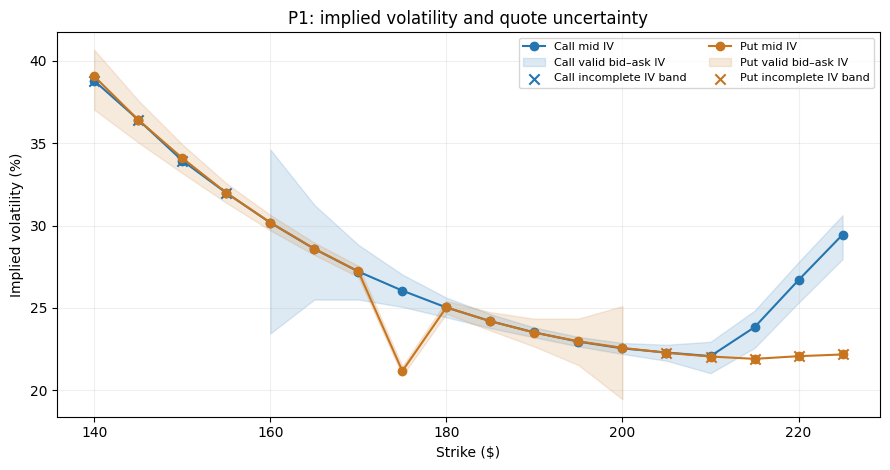

In [3]:
iv = ex.chain_implied_volatilities(chain,S1,T1,r1,q1)
display(iv[["Type","Strike","BidIV","MidIV","AskIV","Vega","OneCentVolPoints"]])
display(iv.loc[(iv.BidStatus!="OK") | (iv.MidStatus!="OK") | (iv.AskStatus!="OK"), ["Type","Strike","BidStatus","MidStatus","AskStatus"]])
fig, ax = plt.subplots()
colors={"Call":"#2475b0","Put":"#c87520"}
for kind in ["Call","Put"]:
    x = iv.loc[iv.Type==kind]
    valid=x[["BidIV","AskIV"]].notna().all(axis=1)
    ax.plot(x.Strike,100*x.MidIV,"o-",color=colors[kind],label=kind+" mid IV")
    ax.fill_between(x.loc[valid,"Strike"],100*x.loc[valid,"BidIV"],100*x.loc[valid,"AskIV"],color=colors[kind],alpha=.15,label=kind+" valid bid–ask IV")
    ax.scatter(x.loc[~valid,"Strike"],100*x.loc[~valid,"MidIV"],marker="x",s=55,color=colors[kind],label=kind+" incomplete IV band")
ax.set(xlabel="Strike ($)", ylabel="Implied volatility (%)", title="P1: implied volatility and quote uncertainty")
ax.legend(ncol=2,fontsize=8); plt.tight_layout(); plt.show()

### Reconcile (f–h)
The following table translates the parity gap to volatility points using each side's local vega. This is a first-order estimate; call and put vegas at two different fitted volatilities are not identical. The observed IV gap should lie near these local approximations.

The far call wing above 210 must be judged against its bid–ask IV interval and one-cent sensitivity. The high-strike puts are also poorly conditioned: their bid IV is undefined below the no-arbitrage bound and their vega becomes very small. The plot marks mid-IV points whose full bid–ask IV band cannot be drawn, rather than letting a missing band look like zero uncertainty. After excluding the inconsistent strike and unreliable far wings, compare the clean downside and upside IVs: a higher downside IV is consistent with stronger demand for crash protection, not a literal forecast of different realized volatilities for each strike.

In [4]:
comparison=ex.parity_gap_in_vol_points(parity,iv)
display(comparison)
display(iv.loc[iv.Strike.between(165,185),["Type","Strike","Mid","MidIV"]])
display(iv.loc[(iv.Type=="Call")&(iv.Strike>210),["Strike","Mid","BidIV","MidIV","AskIV","Vega","OneCentVolPoints"]])
display(iv.loc[(iv.Type=="Put")&(iv.Strike>210),["Strike","Mid","BidIV","MidIV","AskIV","Vega","OneCentVolPoints"]])

,Strike,Parity gap,Gap / call vega (vol points),Gap / put vega (vol points),Observed call-put IV (vol points),Parity-consistent put mid,Parity-consistent call mid
0,175.000000,0.888179,4.713898,5.104231,4.883675,2.598179,9.716821


,Type,Strike,Mid,MidIV
5,Call,165.000000,18.875000,0.285822
6,Call,170.000000,14.535000,0.272050
7,Call,175.000000,10.605000,0.260457
8,Call,180.000000,7.230000,0.250206
9,Call,185.000000,4.555000,0.241920
23,Put,165.000000,0.910000,0.285929
24,Put,170.000000,1.550000,0.272151
25,Put,175.000000,1.710000,0.211620
26,Put,180.000000,4.205000,0.250305
27,Put,185.000000,6.505000,0.241808


,Strike,Mid,BidIV,MidIV,AskIV,Vega,OneCentVolPoints
15,215.000000,0.075000,0.225619,0.238225,0.248267,2.258016,0.442867
16,220.000000,0.075000,0.253138,0.266888,0.277811,2.073255,0.482333
17,225.000000,0.075000,0.279646,0.294473,0.306226,1.925035,0.519471


,Strike,Mid,BidIV,MidIV,AskIV,Vega,OneCentVolPoints
33,215.000000,31.870000,NaN,0.219007,0.335862,1.460265,0.684807
34,220.000000,36.825000,NaN,0.220618,0.379250,0.658182,1.519338
35,225.000000,41.795000,NaN,0.221676,0.424353,0.271628,3.681510


### Observed results — Problem 1
Only **K = 175** is flagged: the mid-price parity gap is **\$0.88818**, exceeding the **\$0.47** combined spread band. Its call IV is **26.0457%**, while its put IV is **21.1620%**, a **4.8837 vol-point** difference. Dividing the dollar gap by call or put vega gives about **4.71–5.10 vol points**, agreeing with the actual gap to first order. Parity alone identifies only a relative inconsistency. Within this chain, however, the call IV lies smoothly between K=170 and 180 while the put has an isolated trough and local strike-shape break. That evidence strongly points to an underpriced K=175 put: raising its **\$1.71** midpoint by the parity gap gives about **\$2.59818** and restores the call-consistent IV. A trustworthy feed would still be needed for definitive quote attribution.

At K = **215, 220, 225**, call mids are all **\$0.075**. Their IVs mechanically rise to **23.82%, 26.69%, and 29.45%**, despite progressively higher strikes. A one-cent price change moves these IVs by **0.44, 0.48, and 0.52 vol points**, and their bid–ask IV ranges are approximately **22.56–24.83%, 25.31–27.78%, and 27.96–30.62%**. The quoted ranges themselves shift upward: this is a suspicious floor/stale-quote pattern, not merely a plotting artifact. Tiny dollar time values and very wide ITM put spreads permit the corresponding parity gaps to remain inside their dollar bands.

Away from these issues, downside volatility is much higher: the K=140 put is about **39.07%** and near-ATM K=180 is about **25.03%**. The high-strike put mid-IVs approach 22%, but they are not reliable anchors: at K=215, 220, and 225, vega falls to about **1.46, 0.66, and 0.27**, so one cent moves IV by approximately **0.68, 1.52, and 3.68 vol points**. This leaves a pronounced downside skew in the better-conditioned quotes, consistent with demand for downside insurance. Several deep-ITM bids are below discounted intrinsic value; their missing bid IVs are economically required, not a solver failure.

## Problem 2 — American options and discrete dividends

**Classroom basis:** Week 7, *When Early Exercise Pays*, *American Options with Discrete Dividends*, *When Early Exercise Is Optimal*, and *Numerical Derivatives*.

Backward induction discounts the risk-neutral continuation value; the American tree additionally takes its maximum with immediate intrinsic value. A cash dividend maps the stock node $S^-$ to $S^+=S^--D$; subtracting a fixed dollar amount breaks the multiplicative recombination identity, so a new subtree is needed at each ex-dividend node. European options use the same cash drops but cannot take the early-exercise maximum.

Before the final dividend, the call exercise boundary solves
$$S^*-K=C_{\mathrm{continuation}}(S^*-D,T-t_d).$$
The condition $D>K(1-e^{-r(T-t_d)})$ compares dividend capture with the interest lost by paying K early. It is a possibility test for sufficiently ITM exercise, not a guarantee for every S. The no-dividend American call has no early-exercise benefit because retaining the option preserves optionality while postponing K. The put can benefit from receiving K early, so it may have an early-exercise premium even without dividends.

The finite-difference formulas in the notes assume local smoothness. A fixed finite tree violates that assumption at payoff/exercise kinks. Both discretization and cancellation error must therefore be considered before trusting a tiny-bump gamma.

### Predict (a–b)
Compare each dividend with $K[1-e^{-r(T-t_d)}]$. Passing this condition makes early call exercise possible for sufficiently high stock prices; it does not imply exercise at the current spot. The late \$1.50 dividend should pass, and the earlier \$0.25 dividend should fail. Both dividends reduce the ex-dividend stock price, lowering European and American calls and raising puts. The call early-exercise premium should grow because exercise can capture the late dividend; the put premium should shrink because waiting captures the downward price adjustment.

### Fit (c–d)
The two dividend dates are exact grid points for every displayed N. Both dividend-paying European and American values use non-recombining subtrees. Only the separate approximation column subtracts PV(dividends) from spot before GBSM. Finite-tree error can produce a small American-minus-GBSM difference even for a no-dividend call.

,Time,Dividend,Interest threshold,Condition met
0,0.100000,0.250000,0.891948,False
1,0.400000,1.500000,0.224495,True


,European no div,European no-div tree,American no div,European dividends,American dividends
Type,,,,,
Call,3.922268,3.917604,3.917604,3.175174,3.467544
Put,4.309830,4.305166,4.435280,5.284855,5.371135


,PV-adjusted GBSM,PV approx minus tree,EEP no div,EEP dividends,European tree minus GBSM no div,American tree minus GBSM no div
Type,,,,,,
Call,3.072293,-0.102881,0.000000,0.292370,-0.004664,-0.004664
Put,5.181974,-0.102881,0.130115,0.086280,-0.004664,0.125450


,N,Call,Put
0,50,3.471515,5.367981
1,55,3.484165,5.384513
2,100,3.472648,5.379319
3,105,3.465115,5.368243
4,150,3.468253,5.369322
5,155,3.473938,5.375729
6,200,3.467544,5.371135
7,205,3.467231,5.372829
8,300,3.469960,5.372075


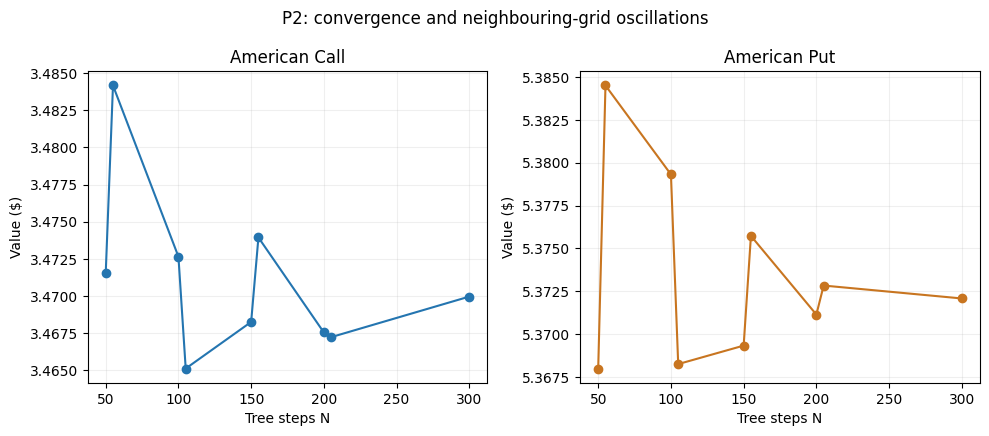

In [5]:
S2,K2,T2,r2,v2 = 48.50,50.,.5,.045,.30
divs,times = [.25,1.50],[.10,.40]
N2 = 200
conditions = ex.dividend_exercise_conditions(K2,T2,r2,times,divs)
display(conditions)
prices2 = ex.dividend_option_comparison(S2,K2,T2,r2,v2,N2,divs,times)
display(prices2[["European no div","European no-div tree","American no div","European dividends","American dividends"]])
display(prices2[["PV-adjusted GBSM","PV approx minus tree","EEP no div","EEP dividends","European tree minus GBSM no div","American tree minus GBSM no div"]])
convergence2 = ex.dividend_tree_convergence(S2,K2,T2,r2,v2,divs,times,[50,55,100,105,150,155,200,205,300])
display(convergence2)
fig,axes=plt.subplots(1,2,figsize=(10,4.4))
for j,name in enumerate(["Call","Put"]):
    axes[j].plot(convergence2.N,convergence2[name],"o-",color=["#2475b0","#c87520"][j])
    axes[j].set(title="American "+name,xlabel="Tree steps N",ylabel="Value ($)")
fig.suptitle("P2: convergence and neighbouring-grid oscillations")
plt.tight_layout();plt.show()

### Fit (e–f)
Delta uses $[V(S+h)-V(S-h)]/(2h)$ and gamma uses $[V(S+h)-2V(S)+V(S-h)]/h^2$. N is held fixed at 200 to isolate bump sensitivity. Dividend sensitivities use symmetric \$0.001 bumps, holding the stock price and all other inputs fixed; values are dollars of option value per dollar of dividend.

In [6]:
greeks2 = ex.dividend_tree_greeks(S2,K2,T2,r2,v2,N2,divs,times,[1.,.1,.01,.001])
sens2 = ex.dividend_sensitivities(S2,K2,T2,r2,v2,N2,divs,times)
boundary2 = ex.last_dividend_call_boundary(K2,T2-times[1],r2,v2,divs[1],40)
display(greeks2);display(sens2)
print(f"Exercise boundary just BEFORE the second dividend, N=200 grid: ${boundary2:.6f}")
print("Exercise is optimal above this threshold; the dividend is subtracted in continuation value.")

,Type,Bump,Delta,Gamma
0,Call,1.000000,0.504181,0.045907
1,Call,0.100000,0.500283,0.078617
2,Call,0.010000,0.504176,0.004575
3,Call,0.001000,0.504187,0.000000
4,Put,1.000000,-0.544792,0.041350
5,Put,0.100000,-0.561180,0.021055
6,Put,0.010000,-0.561678,0.017833
7,Put,0.001000,-0.561684,0.022390


,Option,dV/dD1,dV/dD2
0,European Call,-0.425874,-0.371685
1,American Call,-0.483863,-0.084200
2,European Put,0.569636,0.610476
3,American Put,0.576026,0.617161


Exercise boundary just BEFORE the second dividend, N=200 grid: $52.724852
Exercise is optimal above this threshold; the dividend is subtracted in continuation value.


### Reconcile (g–i)
The early-exercise premiums and boundary above distinguish a possible exercise opportunity from unconditional exercise. The call can be exercised immediately before the large late dividend when intrinsic value exceeds continuation after the cash drop. The smaller first dividend is not large enough to compensate for the remaining interest cost of paying the strike early.

Gamma is the unstable Greek: at fixed N, the tree value is piecewise linear in spot. A small bump inside one linear segment yields essentially zero gamma; crossing a kink produces a spike. Reducing h without refining N does not recover the smooth continuous-model gamma. Delta is piecewise constant and is much less sensitive away from a kink. The N=200 value is a discretization choice, not an exact limit; the convergence table exposes the remaining error.

The earlier dividend affects the stock carried through the remaining life. Much of a late dividend's effect on an American call is avoided in high-price states by exercising just beforehand, reducing the late dividend's marginal effect relative to a European call. The first dividend cannot itself trigger exercise, and increasing it also shifts the later stock distribution down, reducing the value and probability of the second-dividend exercise opportunity. That interaction can make the American call more sensitive to the first dividend than the European call. The sign and ordering are stable across smaller dividend bumps, although their exact magnitudes still oscillate with N.

### Observed results — Problem 2
The dividend thresholds are approximately **\$0.892** at t=0.10 and **\$0.224** at t=0.40. Thus only the \$1.50 second dividend passes the stated early-call-exercise condition. At N=200, with dividends, European/American call prices are **\$3.17517 / \$3.46754**, and European/American put prices are **\$5.28486 / \$5.37114**. Both call values fall and both put values rise, as predicted. PV-adjusted GBSM understates each European dividend-tree value by about **\$0.10288** because subtracting dividend PV at time zero makes the adjusted stock lognormal and applies volatility only to that reduced base. A fixed cash drop instead makes the true stock process non-lognormal and leaves more absolute pre-dividend price uncertainty; the simple adjustment therefore understates time value here.

Using the same N=200 tree for the American and European values, the call's early-exercise premium rises from numerical zero without dividends to **\$0.29237** with dividends. The put premium falls from approximately **\$0.13011** to **\$0.08628**. The no-dividend European tree is **\$0.00466 below** exact GBSM for both calls and puts; keeping that discretization error separate prevents it from contaminating the early-exercise premium.

Neighbouring grids oscillate: N=100 and 105 give calls **\$3.47265 / \$3.46512**, while N=200 and 300 give **\$3.46754 / \$3.46996**. At the N=200 post-dividend subtree resolution, call exercise just before the second dividend becomes optimal above about **\$52.72485**. This is a tree-dependent boundary.

Call gamma is **0.04591, 0.07862, 0.00458, and approximately 0** as h shrinks from 1 to 0.001; put gamma is also bump-sensitive (**0.04135, 0.02105, 0.01783, 0.02239**). The piecewise-linear tree explains this lack of stable gamma. American-call sensitivities are **−0.48386** to the first dividend and only **−0.08420** to the second, versus European-call sensitivities **−0.42587 / −0.37169**. Early exercise protects the American call from much of the late cash drop.

## Problem 3 — VaR of an option book

**Classroom basis:** Week 4, delta-normal risk; Week 5, *The Normal Case* and *What ES Costs*; Week 7, *The Main Greeks* and *Hedging Example*.

Let $\delta_P=\sum h_i\delta_i$, $\Gamma_P=\sum h_i\Gamma_i$, and $\Theta_P=\sum h_i\Theta_i$. Stock contributes delta 1 and zero gamma/theta. The local approximation is
$$\Delta P\approx\delta_P\Delta S+\tfrac12\Gamma_P(\Delta S)^2+\Theta_P\Delta t.$$
Delta-normal keeps only the first term. With independent zero-mean daily returns and daily volatility $\sigma_d$, its ten-day P&L standard deviation is
$$s_P=|\delta_P|S_0\sigma_d\sqrt{10},\quad
VaR_\alpha=-s_P\Phi^{-1}(\alpha),\quad ES_\alpha=s_P\frac{\phi(\Phi^{-1}(\alpha))}{\alpha}.$$
A short-gamma portfolio has a negative quadratic term for both signs of $\Delta S$. This is exactly the mechanism in the lecture's delta-hedged short-call example; setting the linear term to zero cannot eliminate that loss.

Full revaluation instead uses $S_{10}=S_0\prod_{d=1}^{10}(1+r_d)$ and reprices at $T-10/255$. For small moves, its expected P&L is approximately $\Theta_P\Delta t+\tfrac12\Gamma_PE[(\Delta S)^2]$ when $E[\Delta S]=0$. This explains why flat-price theta gains and simulated means differ. ES averages losses beyond the quantile, so a heavy-tailed return model and nonlinear book can change ES substantially even when moderate VaR barely moves.

### Predict (a–b)
Compute the positions' analytic Greeks first, before fitting or simulating returns. Theta is calendar-time decay per year; its ten-day contribution is Theta × 10/255. The signed Greeks below support the explicit pre-simulation ranking recorded immediately after them.

In [7]:
price3 = pd.read_csv(DATA / "problem3.csv",parse_dates=["Date"])
holdings = pd.read_csv(DATA / "problem3_portfolios.csv")
S3 = float(price3.ABC.iloc[-1])
# Arithmetic returns: use the existing coursework return calculation.
ret3 = calculate_returns(price3,method="DISCRETE",date_column="Date")["ABC"]
greeks3 = ex.option_book_greeks(holdings,S3,.0425)
display(greeks3)
print("Last spot:",S3,"; daily returns:",len(ret3))

,Value,Delta,Gamma,Theta
Portfolio,,,,
CoveredCall,9744.780577,69.916054,-3.792522,1477.776381
ShortStraddle,-788.439394,-0.888844,-8.092138,3313.354940
RiskReversal,-65.793049,61.388729,0.535962,18.588445
HedgedShortCall,4580.842699,-0.444422,-4.046069,1868.117622


Last spot: 99.12 ; daily returns: 500


**Prediction after Greeks, before distribution fitting and simulation:** all four books have positive theta, so I predict a gain if ABC is unchanged for ten days; the risk reversal should have the smallest gain because its net theta is only slightly positive. I expect the largest proportional delta-normal errors in the hedged short call and near-delta-neutral short straddle because their near-zero deltas hide large negative gamma. Covered-call downside should also be understated as the short call loses delta on a selloff. The positive-gamma risk reversal should have the smallest moderate-quantile error and may have downside VaR modestly overstated by delta-only risk, although its asymmetric legs can overturn that result in the far tail. I expect the two short-gamma books to have ES/VaR ratios clearly above the Normal benchmark.

### Fit (c–e)
Report the first four sample moments (fourth = **excess** kurtosis). Fit Normal and Student-t by MLE and compare AICc. The Student-t `sigma` is a scale, not its standard deviation; for nu > 2 its standard deviation is scale × √[nu/(nu−2)]. For simulation, set the fitted location to zero while preserving fitted scale and degrees of freedom.

Delta-normal uses the Normal MLE daily sigma, linear exposure delta × spot, and √10. Full revaluation uses 200,000 independent ten-day paths per model, compounds daily arithmetic returns, reduces maturity by exactly ten trading days, and holds IV constant. Invalid returns below −100% cause an explicit error rather than clipping. Results are Monte Carlo estimates, particularly noisy at 1%; the fixed seeds make the reported realization reproducible.

In [8]:
flat3 = ex.option_book_pnl(holdings,S3,np.array([S3]),.0425)
print("Exact P&L with stock unchanged for ten days:");display(flat3)
display(pd.DataFrame([sample_moments(ret3)],index=["ABC daily arithmetic returns"]))
models3, fits3 = ex.distribution_comparison(ret3)
display(fits3)
print("Lowest AICc:",fits3.AICc.idxmin())
dn3 = ex.delta_normal_risk(greeks3,S3,models3["Normal"].sigma)
display(dn3)
spots3={}; pnl3={}; risk3={}; approx3={}
for i,(name,model) in enumerate(models3.items()):
    spots3[name]=ex.zero_mean_terminal_spots(model,S3,10,200000,545+i)
    pnl3[name]=ex.option_book_pnl(holdings,S3,spots3[name],.0425)
    risk3[name]=ex.pnl_risk_table(pnl3[name])
    approx3[name]=ex.pnl_risk_table(ex.taylor_book_pnl(greeks3,S3,spots3[name]))
    display(pd.concat({name+" - Full revaluation":risk3[name]}, names=["Model / method"]))
    display(pd.concat({name+" - Delta + gamma + theta":approx3[name]}, names=["Model / method"]))

Exact P&L with stock unchanged for ten days:


,CoveredCall,ShortStraddle,RiskReversal,HedgedShortCall
0,60.553437,143.055836,3.728685,79.826602


,Mean,Variance,Skewness,Excess Kurtosis
ABC daily arithmetic returns,0.000321,0.000278,0.019116,2.463937


,mu,sigma,AICc,nu
Model,,,,
Normal,0.000321,0.016674,-2671.924954,NaN
Student-t,0.000001,0.013506,-2700.348656,5.789181


Lowest AICc: Student-t


,P&L std,VaR 5%,ES 5%,VaR 1%,ES 1%
Portfolio,,,,,
CoveredCall,365.414176,601.052833,753.744501,850.080491,973.907058
ShortStraddle,4.645516,7.641194,9.582365,10.807086,12.381295
RiskReversal,320.846370,527.745315,661.813917,746.400271,855.124308
HedgedShortCall,2.322758,3.820597,4.791183,5.403543,6.190648


Mean     VaR 5%      ES 5%  ES/VaR 5%      VaR 1%       ES 1%  ES/VaR 1%
Model / method            Portfolio                                                                                    
Normal - Full revaluation CoveredCall      6.334869 679.826559 877.378270   1.290591 1000.945485 1162.900787   1.161802
                          ShortStraddle   19.541089 318.756458 490.631613   1.539205  595.694146  758.539917   1.273371
                          RiskReversal     8.698244 491.383205 644.208910   1.311011  738.530943  877.158934   1.187708
                          HedgedShortCall 18.069229 151.079545 237.017122   1.568823  289.548389  370.971274   1.281206

Mean     VaR 5%      ES 5%  ES/VaR 5%      VaR 1%       ES 1%  ES/VaR 1%
Model / method                 Portfolio                                                                                    
Normal - Delta + gamma + theta CoveredCall      6.229964 661.748996 880.360623   1.330354 1015.114431 1210.087288   1.192070
                               ShortStraddle   19.145236 297.887027 500.405273   1.679849  619.834072  841.737107   1.358004
                               RiskReversal     8.242783 495.248187 607.941738   1.227550  678.648444  767.206251   1.130491
                               HedgedShortCall 17.864389 140.651743 241.910866   1.719928  301.625265  412.576783   1.367846

Mean     VaR 5%      ES 5%  ES/VaR 5%      VaR 1%       ES 1%  ES/VaR 1%
Model / method               Portfolio                                                                                    
Student-t - Full revaluation CoveredCall      6.478751 678.693452 896.142545   1.320394 1030.624808 1222.730353   1.186397
                             ShortStraddle   20.101355 322.142353 520.190101   1.614783  640.818988  844.946482   1.318542
                             RiskReversal     8.361180 490.565152 660.284735   1.345967  762.921802  930.670910   1.219877
                             HedgedShortCall 18.349362 152.772492 251.796366   1.648179  312.110809  414.174557   1.327011

Mean     VaR 5%      ES 5%  ES/VaR 5%      VaR 1%       ES 1%  ES/VaR 1%
Model / method                    Portfolio                                                                                    
Student-t - Delta + gamma + theta CoveredCall      6.035271 660.558217 903.256413   1.367414 1049.474218 1286.413266   1.225769
                                  ShortStraddle   19.031144 302.446496 537.801607   1.778171  667.658343  966.466108   1.447546
                                  RiskReversal     8.127194 494.581986 618.179868   1.249904  695.141146  799.210383   1.149710
                                  HedgedShortCall 17.807343 142.931478 260.609033   1.823314  325.537401  474.941283   1.458945

### Fit (f) — P&L shape
Full revaluation includes time decay. The delta-only line deliberately omits gamma and theta, matching the delta-normal approximation.

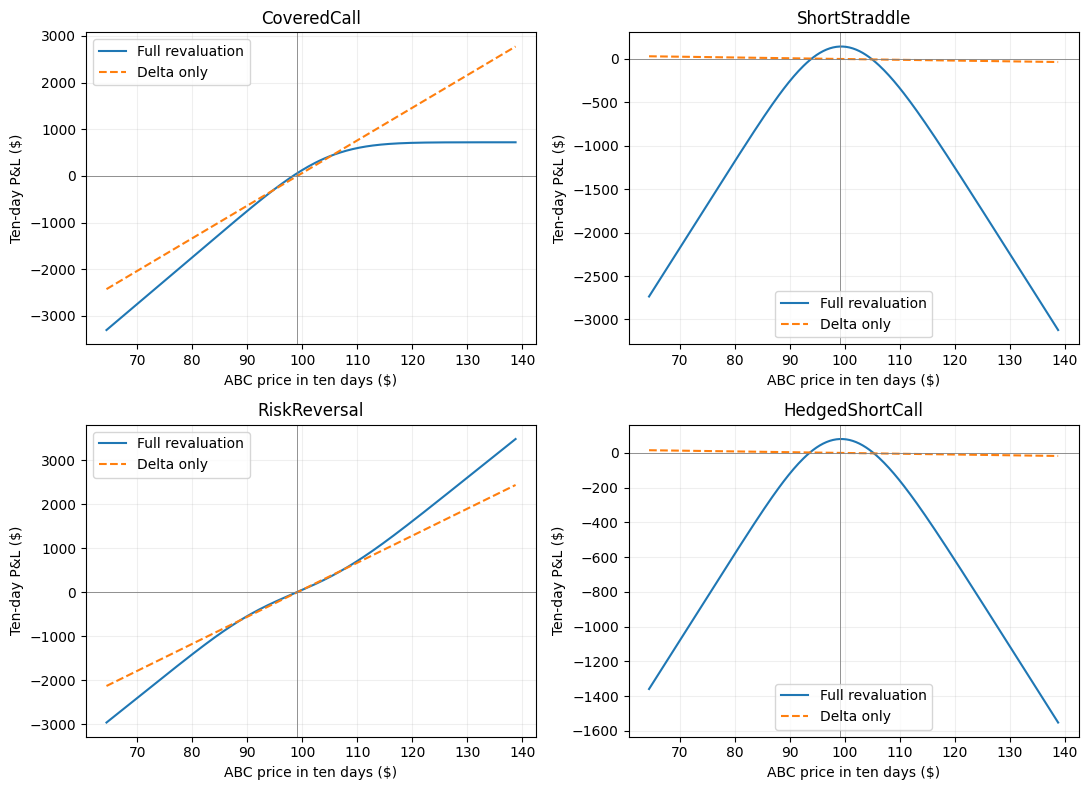

In [9]:
grid3=np.linspace(.65*S3,1.4*S3,250)
curve3=ex.option_book_pnl(holdings,S3,grid3,.0425)
delta_curve3=ex.delta_only_pnl(greeks3,S3,grid3)
fig,axes=plt.subplots(2,2,figsize=(11,8))
for ax,name in zip(axes.flat,curve3):
    ax.plot(grid3,curve3[name],label="Full revaluation")
    ax.plot(grid3,delta_curve3[name],"--",label="Delta only")
    ax.axhline(0,color="grey",lw=.6);ax.axvline(S3,color="grey",lw=.6)
    ax.set(title=name,xlabel="ABC price in ten days ($)",ylabel="Ten-day P&L ($)");ax.legend()
plt.tight_layout();plt.show()

### Reconcile (g–j)
A near-zero delta makes delta-normal risk nearly zero even though a short-gamma book can lose on moves in **either** direction. The second-order approximation adds ½ Gamma × (ΔS)² and Theta × Δt, and therefore restores an important missing source of risk. It is still a local expansion: Greeks vary over a ten-day move and near expiry, so it cannot exactly reproduce full repricing, especially in extreme tails. The approximation tables quantify the residual error using identical simulated terminal prices.

A flat-stock gain measures time decay, not expected total P&L. Under stochastic prices, negative gamma offsets that gain; a positive simulated mean, if present, compensates the short-option book for large adverse moves and reflects implied volatility relative to the fitted return volatility. It is not arbitrage income. A fitted t usually changes 1% ES more than 5% VaR because its far tails differ most from a Normal, while its central quantiles can remain similar. The exact book-level changes are shown below.

**Two sentences to the risk manager:** The hedged short call is delta-flat only locally; it remains short gamma and exposed to time decay, volatility changes, and large stock moves. Its ten-day VaR and ES require full revaluation or an explicitly validated nonlinear approximation, not a zero-risk label.

In [10]:
print("Student-t minus Normal full-revaluation risk:")
display(risk3["Student-t"][["Mean","VaR 5%","ES 5%","VaR 1%","ES 1%"]]-risk3["Normal"][["Mean","VaR 5%","ES 5%","VaR 1%","ES 1%"]])
print("Full-revaluation VaR divided by delta-normal VaR (large ratios indicate underestimation):")
display(pd.DataFrame({name:risk3[name]["VaR 1%"]/dn3["VaR 1%"] for name in models3}))
print("Student-t Taylor mean decomposition:")
mean_components3=ex.taylor_mean_components(greeks3,S3,spots3["Student-t"])
display(mean_components3)

Student-t minus Normal full-revaluation risk:


,Mean,VaR 5%,ES 5%,VaR 1%,ES 1%
Portfolio,,,,,
CoveredCall,0.143882,-1.133107,18.764275,29.679324,59.829567
ShortStraddle,0.560266,3.385895,29.558488,45.124841,86.406565
RiskReversal,-0.337063,-0.818053,16.075825,24.390858,53.511976
HedgedShortCall,0.280133,1.692948,14.779244,22.562421,43.203283


Full-revaluation VaR divided by delta-normal VaR (large ratios indicate underestimation):


,Normal,Student-t
Portfolio,,
CoveredCall,1.177471,1.212385
ShortStraddle,55.120698,59.296185
RiskReversal,0.989457,1.022135
HedgedShortCall,53.584913,57.760399


Student-t Taylor mean decomposition:


,Delta contribution,Gamma contribution,Theta contribution,Taylor mean
Portfolio,,,,
CoveredCall,0.060159,-51.976903,57.952015,6.035271
ShortStraddle,-0.000765,-110.903579,129.935488,19.031144
RiskReversal,0.052822,7.345414,0.728959,8.127194
HedgedShortCall,-0.000382,-55.451789,73.259515,17.807343


### Observed results — Problem 3
The 500 returns have mean **0.0003214**, variance **0.0002780**, skewness **0.0191**, and excess kurtosis **2.4639**. Student-t wins AICc (**−2700.35** versus **−2671.92**): its fitted location is **0.00000118**, scale **0.0135062**, and degrees of freedom **5.7892**. The Normal fit has location **0.0003214** and sigma **0.0166743**. Fitting locations are reported, then reset to zero for simulation only.

The short straddle and hedged short call have deltas **−0.88884 / −0.44442** and gammas **−8.09214 / −4.04607**. Under the fitted t, their 1% full-revaluation VaRs are about **\$640.82 / \$312.11**, compared with delta-normal **\$10.81 / \$5.40**. Both are dramatically understated by delta-normal; by proportional error the straddle is slightly worse. Covered-call t 1% VaR is **\$1,030.62** versus delta-normal **\$850.08**. Risk-reversal 5% VaR is **\$490.57** versus **\$527.75**, agreeing with the predicted moderate-quantile overstatement, but its t 1% VaR (**\$762.92**) slightly exceeds delta-normal (**\$746.40**): the local positive gamma prediction does not hold throughout the extreme downside.

All four books gain at a flat stock price after ten days: covered call **\$60.55**, straddle **\$143.06**, risk reversal **\$3.73**, hedged short call **\$79.83**. Their simulated t mean P&Ls are only **\$6.48, \$20.10, \$8.36, and \$18.35**, respectively. For the risk reversal, the local Taylor decomposition makes the mechanism explicit: positive gamma contributes about **\$7** through $\tfrac12\Gamma E[(\Delta S)^2]$, while theta adds about **\$0.73** and the small simulated mean stock move contributes the remaining delta term. The short-gamma books instead lose much of their time-decay-only gain once stochastic price moves are included.

At 5%, t ES/VaR ratios are **1.61** for the straddle and **1.65** for the hedged short call, clearly above the zero-mean Normal benchmark of about **1.254**. At 1%, that benchmark is about **1.146**, not 1.25. Switching Normal to t barely changes the 5% VaRs (roughly **−\$1.13, +\$3.39, −\$0.82, +\$1.69**) but raises 1% ES by about **\$59.83, \$86.41, \$53.51, and \$43.20** in the same book order. The straddle has the largest absolute 1% ES change, and the two short-gamma books have the largest relative changes. This is the far-tail and convexity interaction anticipated in the prediction.

Gamma plus theta improves the near-zero-delta diagnosis but does not reproduce repricing: for example, t straddle 1% ES is approximately **\$966.47** under the Taylor approximation versus **\$844.95** under full revaluation. For the risk reversal the approximation instead understates t 1% ES (**\$799.21** versus **\$930.67**).

## Problem 4 — A Sharpe ratio that sells insurance

**Classroom basis:** Week 7, *The Markowitz Problem*, *The Sharpe Ratio and the Capital Market Line*, and *CAPM*; Week 5, *Expected Shortfall* and *Coherence and Convexity*.

The Sharpe objective is
$$SR(w)=\frac{w^T\mu-r_f}{\sqrt{w^T\Sigma w}},\qquad\mathbf1^Tw=1.$$
It uses only two moments. A capped-gain, crash-loss payoff can have the same mean and variance as a much less asymmetric payoff, so its skewness is not separately penalized by this objective. Selling a put adds a loss proportional to $\max(K-S_T,0)$; the cash collateral prevents borrowing but does not eliminate this contingent liability.

For continuous P&L, positive-loss ES is $-E[P\mid P\le q_\alpha(P)]$. Its response to the worst losses follows from that tail average. Coherence additionally gives monotonicity and subadditivity, allowing risk comparisons and diversification without VaR's aggregation pathology. Standard deviation is subadditive but **not monotone**, a distinction explicitly made in Week 7; coherence alone should not be mistaken for a promise that ES estimates are precise.

Sampling uncertainty enters through $SE(\bar r_i)=s_i/\sqrt{240}$. The unconstrained tangency direction is $\Sigma^{-1}(\mu-r_f\mathbf1)$, so uncertainty in means is transformed and can be amplified by the inverse covariance. This motivates inspecting bootstrap weights rather than treating a numerical optimum as a precisely estimated economic allocation.

### Predict (a–b)
The PUTW strategy earns a limited option premium in ordinary months while retaining a large downside loss when EQ falls sufficiently far. I expect negative skewness and elevated kurtosis, with a disproportionate contribution from an extreme month. Compute the descriptive diagnostics first; the numerical portfolio-weight prediction is recorded after those diagnostics and before optimization, as the question requests.

In [11]:
returns4=pd.read_csv(DATA / "problem4.csv",parse_dates=["Month"]).set_index("Month")
rf4=.03/12
diag4=ex.asset_diagnostics(returns4,rf4,12)
display(diag4[["Mean","Variance","Skewness","Excess Kurtosis","Annual Sharpe","Mean SE"]])
display(diag4[["Extreme date","Extreme return","Fourth moment share","Excess kurtosis without extreme"]])
print("Monthly observations:",len(returns4))

,Mean,Variance,Skewness,Excess Kurtosis,Annual Sharpe,Mean SE
Asset,,,,,,
EQ,0.007901,0.002427,-0.387345,3.519014,0.379790,0.003180
BOND,0.003327,0.000181,0.087219,0.517161,0.212761,0.000869
STK,0.011244,0.008699,-0.061011,0.811965,0.324782,0.006020
PUTW,0.006243,0.000274,-6.566535,61.141773,0.783391,0.001068


,Extreme date,Extreme return,Fourth moment share,Excess kurtosis without extreme
Asset,,,,
EQ,2008-06-30 00:00:00,-0.235098,0.387254,1.916803
BOND,2012-12-31 00:00:00,0.049857,0.172361,0.205949
STK,2008-06-30 00:00:00,-0.376683,0.333537,-0.084346
PUTW,2008-06-30 00:00:00,-0.167197,0.806143,40.744098


Monthly observations: 240


**Prediction after descriptive diagnostics, before optimization:** PUTW has the largest standalone Sharpe but extreme negative skew and kurtosis. Because the optimizer sees only mean and covariance, I expect it to give PUTW a majority weight, roughly **60%–80%**, rather than penalizing the crash shape directly. I also predict that the long-only portfolio's historical 1% ES will be far above a same-mean/same-volatility Normal ES.

### Fit (c–e)
All portfolios sum to one. The unconstrained tangency solution permits shorting and leverage; the other two have weights in [0,1], with PUTW additionally capped at 0.20 in the third. Historical risk uses the existing coursework order-statistic convention, including all observations at or below its VaR threshold. At 1% with 240 months, only about two or three observations determine historical ES, so it is a fragile estimate. Normal risk uses the same sample mean and sample standard deviation as the portfolio.

CAPM uses monthly excess returns, an intercept, and an explicitly separate regression restricted to EQ excess returns below −5%.

In [12]:
weights4=ex.tangency_portfolios(returns4,rf4,"PUTW",.20)
risk4=ex.portfolio_risk_comparison(returns4,weights4,rf4,12)
display(weights4)
display(risk4[["Mean","Annual Sharpe","VaR 5%","ES 5%","VaR 1%","ES 1%"]])
display(risk4[["Normal VaR 5%","Normal ES 5%","Normal VaR 1%","Normal ES 1%"]])
frontier4=ex.efficient_frontier(returns4)
capm_comparison4=ex.capm_with_downside(returns4,rf4,"PUTW","EQ",-.05)
capm4=capm_comparison4["full"]
tailcapm4=capm_comparison4["downside"]
down4=capm_comparison4["downside_mask"]
print("All months CAPM");display(capm4["coefficients"])
print("R2:",capm4["R2"],"; downside observations:",int(down4.sum()))
print("Down-market CAPM");display(tailcapm4["coefficients"])
print("Down-market R2:",tailcapm4["R2"])

,Unconstrained,Long only,Capped
EQ,-0.043872,0.000000,0.146255
BOND,0.246502,0.260682,0.636209
STK,0.022690,0.009189,0.017536
PUTW,0.774680,0.730129,0.200000


,Mean,Annual Sharpe,VaR 5%,ES 5%,VaR 1%,ES 1%
Portfolio,,,,,,
Unconstrained,0.005565,0.819777,0.003743,0.028977,0.059075,0.103348
Long only,0.005529,0.815294,0.002899,0.029258,0.059994,0.102646
Capped,0.004718,0.590163,0.015592,0.028369,0.039341,0.059731


,Normal VaR 5%,Normal ES 5%,Normal VaR 1%,Normal ES 1%
Portfolio,,,,
Unconstrained,0.015737,0.021149,0.024563,0.028952
Long only,0.015638,0.021015,0.024408,0.028769
Capped,0.016695,0.022135,0.025567,0.029979


All months CAPM


,Coefficient,SE,t
const,0.002745,0.000899,3.051578
EQ,0.184786,0.018186,10.160957


R2: 0.3025539627397208 ; downside observations: 26
Down-market CAPM


,Coefficient,SE,t
const,0.058652,0.003876,15.131673
EQ,0.942847,0.043175,21.838047


Down-market R2: 0.9520862727455354


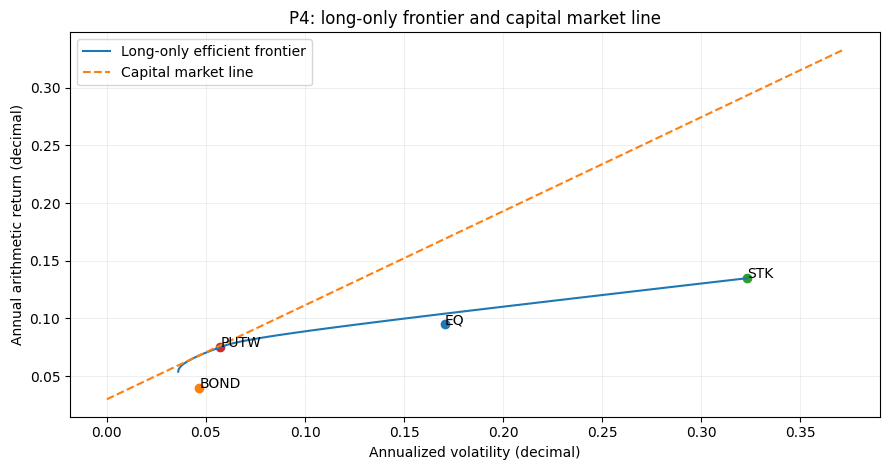

In [13]:
fig,ax=plt.subplots()
ax.plot(frontier4["Monthly std"]*np.sqrt(12),frontier4["Monthly return"]*12,label="Long-only efficient frontier")
stdgrid=np.linspace(0,max(diag4.Std)*np.sqrt(12)*1.15,100)
ax.plot(stdgrid,.03+risk4.loc["Long only","Annual Sharpe"]*stdgrid,"--",label="Capital market line")
for name in returns4:
    ax.scatter(diag4.loc[name,"Std"]*np.sqrt(12),diag4.loc[name,"Mean"]*12)
    ax.annotate(name,(diag4.loc[name,"Std"]*np.sqrt(12),diag4.loc[name,"Mean"]*12))
ax.set(xlabel="Annualized volatility (decimal)",ylabel="Annual arithmetic return (decimal)",title="P4: long-only frontier and capital market line")
ax.legend();plt.tight_layout();plt.show()

### Reconcile (f–h)
The optimizer sees only mean, covariance, and constraints. A strategy that sells crash insurance can look efficient because occasional large losses are compressed into one standard deviation, while their asymmetry and severity are lost. ES averages the worst losses and is coherent: it is monotone, cash-translation invariant, positively homogeneous, and subadditive. These properties permit consistent tail-risk aggregation; they do not remove sampling uncertainty or guarantee a particular portfolio weight.

A positive full-sample CAPM alpha is not by itself evidence of skill. The short put has state-dependent equity exposure: downside beta can be much higher than its full-sample beta. A single straight line does not price this nonlinear payoff properly.

Mean standard errors above measure how imprecise the optimizer's inputs remain even after 240 months. The row bootstrap below jointly resamples all four assets, preserving within-month relationships, and reports the variability of long-only weights. It assumes independent months and is a sensitivity exercise, not a guarantee about future returns. Large weight ranges and frequent boundary solutions should reduce confidence in the exact point weights; a cap limits exposure mechanically, not statistically.

In [14]:
boot4,boot_summary4=ex.bootstrap_tangency(returns4,rf4,replications=200,seed=545)
display(boot_summary4)
print("Successful bootstrap optimizations:",len(boot4),"/ 200")
display(diag4[["Mean","Mean SE","Mean / SE"]])

,Mean,5%,Median,95%
EQ,0.028889,0.000000,0.000000,0.144301
BOND,0.257424,0.000000,0.213287,0.647705
STK,0.019207,0.000000,0.000000,0.097583
PUTW,0.694481,0.190738,0.742193,1.000000


Successful bootstrap optimizations: 199 / 200


,Mean,Mean SE,Mean / SE
Asset,,,
EQ,0.007901,0.003180,2.484594
BOND,0.003327,0.000869,3.828933
STK,0.011244,0.006020,1.867731
PUTW,0.006243,0.001068,5.843470


### Observed results — Problem 4
PUTW has the highest annualized standalone Sharpe, **0.7834**, but skewness **−6.5665** and excess kurtosis **61.1418**. The **2008-06-30** month, returning **−16.7197%**, accounts for **80.61%** of its centered fourth-moment sum. Even after removing that month, excess kurtosis is still **40.7441**, so the tail problem is not eliminated by discarding one observation.

The long-only tangency portfolio gives PUTW **73.01%**, BOND **26.07%**, STK **0.92%**, and essentially zero EQ. Its annual Sharpe is **0.8153**, and its historical monthly 1% ES is **10.2646%**, compared with a Normal estimate of only **2.8769%**. The unconstrained portfolio shorts EQ by **4.39%** and holds **77.47%** PUTW. Capping PUTW at 20% lowers Sharpe to **0.5902**, but lowers historical 1% ES to **5.9731%**. At 5%, Normal VaR can actually exceed historical VaR; the important failure is far-tail severity, not a claim that every Normal statistic is too small.

PUTW's full-sample monthly CAPM alpha is **0.27448%** (t **3.0516**), beta **0.18479**, R² **0.30255**. In the **26** months with EQ excess returns below −5%, beta rises to **0.94285**. This is strong evidence that the single beta conceals insurance exposure.

Monthly mean SEs for EQ/BOND/STK/PUTW are **0.3180%, 0.0869%, 0.6020%, and 0.1068%**. Across 200 bootstrap samples, the long-only PUTW weight's 5th–95th percentile range is approximately **19.07%–100%**, and BOND ranges from **0%–64.77%**. I would not trust the exact tangency percentages. The constrained allocation is more defensible as a deliberate exposure limit, but its remaining weights are still estimation-sensitive.

## Problem 5 — Alpha or factor exposure?

**Classroom basis:** Week 7, *CAPM*, *Arbitrage Pricing Theory*, and *Extensions to CAPM*; Week 2, OLS regression. The FF3 and Carhart equations are already presented in Week 7; no later factor-model lecture is needed for these specifications.

The four-factor regression is
$$r_{i,t}-r_{f,t}=\alpha_i+\beta_{m,i}(r_{m,t}-r_{f,t})+\beta_{s,i}SMB_t+\beta_{h,i}HML_t+\beta_{u,i}Mom_t+\epsilon_{i,t}.$$
Fama–French percentages must be converted to the funds' decimal units. The alpha t-statistic is $\hat\alpha/SE(\hat\alpha)$, so a positive intercept alone is insufficient evidence of an unexplained premium. The model comparison uses
$$AICc=-2\log\hat L+2k+\frac{2k(k+1)}{n-k-1},$$
with k including all regression coefficients and the residual variance.

For an omitted factor write $f_j=a_j+c_j(r_m-r_f)+u_j$ by auxiliary OLS on the market. Substitution into the full model yields
$$\alpha_{CAPM}-\alpha_{4F}=\sum_{j\in\{SMB,HML,Mom\}}\beta_j a_j.$$
This is an application of OLS to the lecture's nested factor specifications. It explains, rather than merely observes, why alpha changes when factors are added. Under the APT expectation equation, changing the factor-premium window changes $E[r_i]=E[r_f]+\alpha_i+\sum_j\beta_{ij}E[f_j]$ even if every estimated beta stays fixed. The momentum-only stress is the same linear exposure applied to one specified shock, $\Delta V=V_0\beta_{u,i}\Delta Mom$.

### Predict (a–b)
Start with realized excess returns and a CAPM. Higher statistically supported CAPM alpha would initially look like greater skill, but a residual correlated with SMB, HML, or momentum suggests omitted systematic exposure. Positive exposure to factors that earned positive premia in the sample should reduce apparent alpha after those factors enter the model; signs of correlations alone are insufficient without the premia. The diagnostics below precede the displayed multifactor estimates.

In [15]:
funds5=pd.read_csv(DATA / "problem5.csv",parse_dates=["Date"]).set_index("Date")
factors5=ex.load_factor_files(DATA / "F-F_Research_Data_Factors_daily.CSV",DATA / "F-F_Momentum_Factor_daily.CSV")
P5_PERIODS=252
joined5,capm_summary5,rescorr5,perf5=ex.capm_fund_diagnostics(funds5,factors5,periods=P5_PERIODS)
assert len(joined5)==len(funds5), "Some fund dates lack factors"
display(perf5)
display(capm_summary5)
display(rescorr5)
print("Sample factor premia:");display(joined5[["Mkt-RF","SMB","HML","Mom"]].mean())
print("Sample:",joined5.index.min().date(),"to",joined5.index.max().date(),"; matched days:",len(joined5))

,Daily excess mean,Daily volatility,Annual Sharpe
Fund,,,
FUND1,0.000624,0.011745,0.842849
FUND2,0.000338,0.007186,0.745616


,Fund,Model,Alpha,Alpha t,R2,AICc
0,FUND1,CAPM,0.000441,3.204331,0.827887,-9812.417711
1,FUND2,CAPM,0.000245,1.834873,0.566886,-9887.500850


,SMB,HML,Mom
Fund,,,
FUND1,-0.061173,0.205203,0.801464
FUND2,0.329526,-0.120633,0.053021


Sample factor premia:


Mkt-RF    0.000216
SMB      -0.000163
HML       0.000372
Mom       0.000782
dtype: float64

Sample: 1996-10-01 to 2001-09-28 ; matched days: 1257


**Prediction after CAPM diagnostics, before fitting FF3/Carhart:** FUND1 looks more skilled under CAPM, but its large positive momentum residual correlation and positive sample momentum premium suggest that adding momentum will substantially reduce its alpha. Positive HML exposure should also absorb part of its apparent alpha. FUND2 has much less momentum residual correlation; its positive SMB residual correlation combined with the negative sample SMB premium could instead raise its alpha after SMB is controlled for. I expect FUND1 to lose much more apparent alpha than FUND2.

### Fit (c–e)
Each regression uses the fund's excess return. Factor files are divided by 100 **once**, and joined by exact date. All models use the identical fund sample. AICc counts every estimated coefficient (including the intercept) **and residual variance**, under Gaussian OLS likelihood. This is a model comparison convention, not proof that residuals are Normal.

The expected-return scenario uses the most recent ten calendar years available in the factor files, not the last ten years of the fund sample. These are explicitly different windows; the recent window is a scenario for future premia, not an out-of-sample historical backtest. Daily means and Sharpe ratios use a stated **252-trading-day** annualization, rather than carrying Problem 3's problem-specific 255-day instruction into this section. The momentum stress sets all other factor shocks flat and excludes alpha and risk-free accrual to isolate momentum exposure.

In [16]:
joined5,fits5,coef5,summary5,rescorr5,perf5=ex.factor_model_comparison(funds5,factors5,periods=P5_PERIODS)
display(coef5)
display(summary5)
projection5,recent5,worst_date5,shock5=ex.factor_projections(funds5,factors5,fits5,periods=P5_PERIODS)
display(projection5)
print("Recent-factor window:",recent5.index.min().date(),"to",recent5.index.max().date(),"; observations:",len(recent5))
print("Recent daily premia:");display(recent5.mean())
print("Worst momentum date:",worst_date5.date(),"; daily momentum return:",shock5)
alpha_decomp5,alpha_recon5=ex.omitted_factor_alpha_reconciliation(joined5,fits5,"FUND1")
display(alpha_decomp5);display(alpha_recon5.to_frame("Value"))

,Fund,Model,Term,Coefficient,SE,t
0,FUND1,CAPM,const,0.000441,0.000138,3.204331
1,FUND1,CAPM,Mkt-RF,0.846890,0.010900,77.696245
2,FUND1,FF3,const,0.000296,0.000131,2.260353
3,FUND1,FF3,Mkt-RF,1.001727,0.017162,58.368824
4,FUND1,FF3,SMB,0.082782,0.020500,4.038191
5,FUND1,FF3,HML,0.334614,0.028812,11.613667
6,FUND1,Carhart4,const,0.000003,0.000070,0.042063
7,FUND1,Carhart4,Mkt-RF,0.949160,0.009166,103.548250
8,FUND1,Carhart4,SMB,0.000835,0.010989,0.075961
9,FUND1,Carhart4,HML,0.290728,0.015329,18.966080


,Fund,Model,Alpha,Alpha t,R2,AICc
0,FUND1,CAPM,0.000441,3.204331,0.827887,-9812.417711
1,FUND1,FF3,0.000296,2.260353,0.845206,-9941.701916
2,FUND1,Carhart4,0.000003,0.042063,0.956333,-11530.407937
3,FUND2,CAPM,0.000245,1.834873,0.566886,-9887.500850
4,FUND2,FF3,0.000277,2.190566,0.614831,-10030.941291
5,FUND2,Carhart4,0.000273,2.149537,0.614896,-10029.134985


,Expected annual without alpha,Expected annual with alpha,Realized annual arithmetic,Realized CAGR,Momentum beta,Stress loss USD,Stress loss / daily std
Fund,,,,,,,
FUND1,0.135438,0.136178,0.206543,0.208124,0.393551,725708.506657,6.178677
FUND2,0.068104,0.136849,0.134447,0.136444,0.005834,10758.421932,0.149713


Recent-factor window: 2014-10-01 to 2024-09-30 ; observations: 2516
Recent daily premia:


Mkt-RF    0.000490
SMB      -0.000047
HML      -0.000094
RF        0.000062
Mom       0.000097
dtype: float64

Worst momentum date: 1939-09-05 ; daily momentum return: -0.1844


,Sample premium,Market-adjusted premium,Full beta,Alpha contribution
Factor,,,,
SMB,-0.000163,-0.000145,0.000835,-0.000000
HML,0.000372,0.000467,0.290728,0.000136
Mom,0.000782,0.000767,0.393551,0.000302


,Value
CAPM alpha,0.000441
Carhart4 alpha,0.000003
Alpha decrease,0.000438
Decomposition sum,0.000438
Reconciliation residual,-0.000000


### Reconcile (f–h)
The alpha decomposition uses each omitted factor's intercept after regressing it on the market. Multiplying these market-adjusted premia by the four-factor betas exactly accounts for the CAPM-to-four-factor alpha change on the same sample. Simply summing beta × raw factor mean would overlook correlation with the included market factor.

In APT, expected returns compensate exposures to systematic risk factors; alpha is the remaining return relative to the chosen factor set and estimation window. Adding a relevant factor can turn apparent skill into a priced exposure. A statistically nonzero alpha remains conditional on the model, standard-error assumptions, and data quality; it does not establish future skill or justify any arbitrary fee.

**Opinion:** I would use the four-factor model, alongside residual diagnostics and fees, to decide which fund merits payment for alpha. I would prefer the fund whose alpha survives those controls with statistical support over one whose CAPM alpha disappears when systematic exposures are included. The executed-results discussion below identifies which fund meets that description here.

Differences between recent-premium projections and realized sample returns show that factor-based expectations still depend on the chosen premium window and on whether alpha persists. For the optimizer in P4, an estimated factor model can structure expected returns, but cannot make them known precisely; use sensitivity ranges and exposure constraints rather than treating the fitted mean as certain.

### Observed results — Problem 5
FUND1 initially looks stronger: 252-day annualized excess-return Sharpe **0.8428** versus FUND2's **0.7456**, and CAPM daily alpha **0.00044066** (t **3.2043**) versus **0.00024491** (t **1.8349**). FUND1's CAPM residual correlation with momentum is **0.8015**, and with HML **0.2052**, indicating omitted factor exposure; FUND2's corresponding momentum correlation is only **0.0530**.

FUND1's alpha falls from **4.4066 basis points/day** under CAPM to **2.9631 bp/day** under FF3 and **0.0294 bp/day** under Carhart4 (t **0.0421**). Its four-factor R² is **0.95633**. FUND2 retains **2.7280 bp/day** of four-factor alpha (t **2.1495**, R² **0.61490**). FF3 has a slightly better AICc than Carhart4 for FUND2 (**−10030.94** versus **−10029.13**), so momentum adds little explanatory value there. Carhart4 is decisively preferred for FUND1.

FUND1's CAPM-to-four-factor alpha decrease is **4.3772 bp/day**. The omitted-factor decomposition attributes approximately **−0.0012 bp** to SMB, **1.3585 bp** to HML, and **3.0199 bp** to momentum. Their sum reconciles the decrease, accounting for correlation with the market.

Using factor observations from **2014-10-01 through 2024-09-30** and 252 trading days, projected annual arithmetic returns excluding/including alpha are **13.5438% / 13.6178%** for FUND1 and **6.8104% / 13.6849%** for FUND2. Realized sample annual arithmetic returns are **20.6543% / 13.4447%**, respectively (CAGRs **20.8124% / 13.6444%**). FUND1's realized return reflects a more favorable sample factor-premium environment; extrapolating it would overstate the recent-premium scenario. FUND2's projection depends strongly on whether its estimated alpha persists.

The worst factor-file momentum return is **−18.44% on 1939-09-05**. With other factors flat, losses on \$10 million are approximately **\$725,709** for FUND1 (**6.18** sample daily standard deviations) and **\$10,758** for FUND2 (**0.15** daily standard deviations). This is a factor-shock scenario, not a Gaussian tail probability.

**Opinion applied to these results:** FUND2 is the stronger candidate for paying an alpha fee; FUND1's apparent alpha is almost entirely factor exposure. I would use the four-factor comparison to detect FUND1's momentum exposure, recognize that FF3 is already adequate for FUND2 here, and require persistence and net-of-fee evidence before committing capital.